# Module 1: Room Revenue & Occupancy Analytics
**Institution:** Invertis University, Bareilly (Faculty of Computer Applications)  
**Project:** ITC Hotels: Revenue & Business Performance Analysis (BCA Final Year Capstone)  
**Project Team:** Jatin Sagar (BC2023727), Atul Kumar (BC2023590), Darshika Rathore (BC2023687), Muskan Saxena (BC2023061)  
**Project Guide:** Ms. Megha Saxena, Assistant Professor  
**Database:** MySQL 8.0 / SQLite 3NF Database (`itc_hotel_analytics.db`)

---
## 1. Executive Summary & Business Context
ITC Hotels is renowned for its luxury hospitality portfolio and *Responsible Luxury* philosophy. Efficient room inventory management is vital for maximizing **RevPAR (Revenue Per Available Room)** while ensuring optimal occupancy throughout seasonal cycles.

This module evaluates room booking patterns, pricing dynamics (ADR), room category upgrades, and reservation stability using both SQL queries and Pandas data structures.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sqlite3
import os
import warnings
warnings.filterwarnings('ignore')

# Matplotlib styling - Academic publication style
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.size'] = 11
plt.rcParams['figure.figsize'] = (12, 6)

# 1. Load Data via SQL Query from itc_hotel_analytics.db
db_path = '../ITC-Final-Dashboards/itc_hotel_analytics.db'
if os.path.exists(db_path):
    conn = sqlite3.connect(db_path)
    sql_query = """
    SELECT 
        r.booking_id,
        r.hotel_name,
        r.arrival_date,
        r.arrival_year,
        r.arrival_month,
        r.arrival_week,
        r.stays_weekend_nights,
        r.stays_week_nights,
        r.total_nights,
        r.reserved_room,
        r.assigned_room,
        r.is_upgraded,
        r.is_canceled,
        r.lead_time,
        i.adr_inr,
        i.room_revenue_inr,
        r.deposit_type,
        r.reservation_status,
        r.status_date,
        r.booking_changes,
        r.days_in_waiting_list
    FROM reservations r
    JOIN invoices i ON r.booking_id = i.booking_id
    """
    df_rooms = pd.read_sql_query(sql_query, conn)
    conn.close()
    print(f"✓ Successfully loaded {len(df_rooms):,} records via SQL query from itc_hotel_analytics.db")
else:
    df_rooms = pd.read_csv('itc_room_revenue_occupancy.csv')
    print(f"✓ Loaded {len(df_rooms):,} records from CSV")

df_rooms.head()

✓ Successfully loaded 87,396 records via SQL query from itc_hotel_analytics.db


,booking_id,hotel_name,arrival_date,arrival_year,arrival_month,arrival_week,stays_weekend_nights,stays_week_nights,total_nights,reserved_room,...,is_upgraded,is_canceled,lead_time,adr_inr,room_revenue_inr,deposit_type,reservation_status,status_date,booking_changes,days_in_waiting_list
0,ITC-2015-000001,ITC Grand Bharat (Luxury Resort),2015-07-01,2015,July,27,0,0,0,Executive Suite,...,0,0,342,0.0,0.0,No Deposit,Check-Out,2015-07-01,3,0
1,ITC-2015-000002,ITC Grand Bharat (Luxury Resort),2015-07-01,2015,July,27,0,0,0,Executive Suite,...,0,0,737,0.0,0.0,No Deposit,Check-Out,2015-07-01,4,0
2,ITC-2015-000003,ITC Grand Bharat (Luxury Resort),2015-07-01,2015,July,27,0,1,1,ITC One Luxury Room,...,1,0,7,6375.0,6375.0,No Deposit,Check-Out,2015-07-02,0,0
3,ITC-2015-000004,ITC Grand Bharat (Luxury Resort),2015-07-01,2015,July,27,0,1,1,ITC One Luxury Room,...,0,0,13,6375.0,6375.0,No Deposit,Check-Out,2015-07-02,0,0
4,ITC-2015-000005,ITC Grand Bharat (Luxury Resort),2015-07-01,2015,July,27,0,2,2,ITC One Luxury Room,...,0,0,14,8330.0,16660.0,No Deposit,Check-Out,2015-07-03,0,0


## 2. Dataset Hygiene & Core KPI Summary

In [2]:
total_bookings = len(df_rooms)
confirmed_bookings = len(df_rooms[df_rooms['is_canceled'] == 0])
canceled_bookings = len(df_rooms[df_rooms['is_canceled'] == 1])
cancellation_rate = (canceled_bookings / total_bookings) * 100

total_room_rev_cr = df_rooms['room_revenue_inr'].sum() / 1e7
avg_adr = df_rooms[df_rooms['is_canceled'] == 0]['adr_inr'].mean()
avg_lead_time = df_rooms['lead_time'].mean()
upgrade_rate = df_rooms['is_upgraded'].mean() * 100

print("="*60)
print(f"ITC ROOM REVENUE & OCCUPANCY EXECUTIVE SCORECARD")
print("="*60)
print(f"Total Reservations       : {total_bookings:,}")
print(f"Confirmed Stays          : {confirmed_bookings:,} ({100 - cancellation_rate:.1f}%)")
print(f"Cancellations            : {canceled_bookings:,} ({cancellation_rate:.1f}%)")
print(f"Total Room Revenue       : ₹ {total_room_rev_cr:,.2f} Crores")
print(f"Average Daily Rate (ADR) : ₹ {avg_adr:,.2f} per room night")
print(f"Average Lead Time        : {avg_lead_time:.1f} days")
print(f"Room Upgrade Rate        : {upgrade_rate:.2f}%")
print("="*60)

ITC ROOM REVENUE & OCCUPANCY EXECUTIVE SCORECARD
Total Reservations       : 87,396
Confirmed Stays          : 63,371 (72.5%)
Cancellations            : 24,025 (27.5%)
Total Room Revenue       : ₹ 292.92 Crores
Average Daily Rate (ADR) : ₹ 8,670.30 per room night
Average Lead Time        : 79.9 days
Room Upgrade Rate        : 15.00%


## 3. Revenue & ADR by ITC Hotel Property Type

,hotel_name,confirmed_stays,total_nights,revenue_crores,mean_adr
0,ITC Grand Bharat (Luxury Resort),25992,109181,91.955211,7902.471649
1,ITC Maurya (City Hotel),37379,111829,103.356990,9204.223511


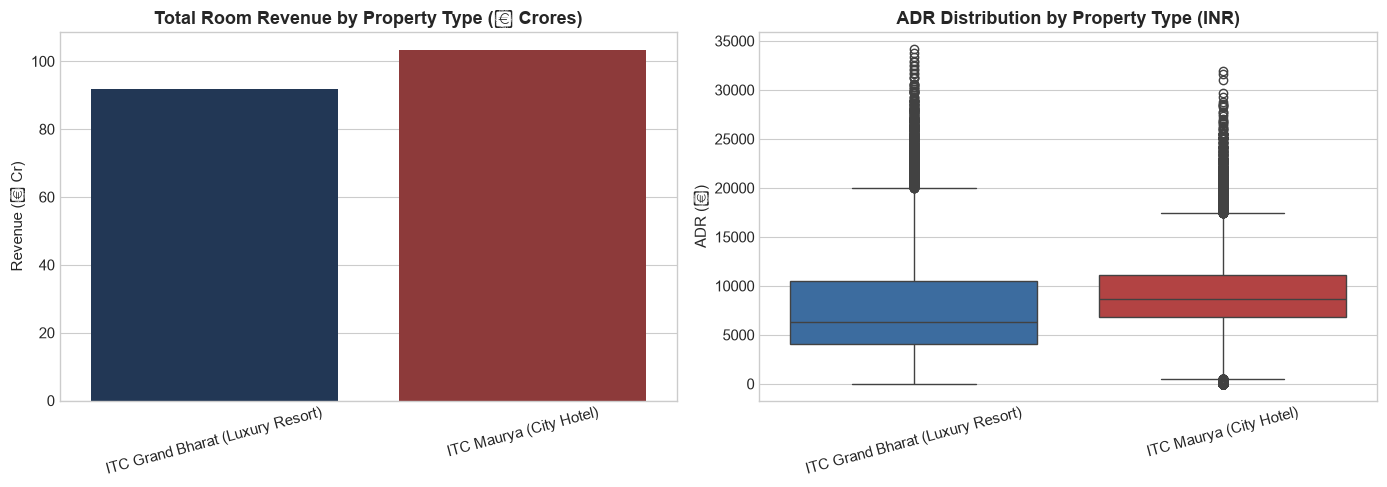

In [3]:
prop_perf = df_rooms[df_rooms['is_canceled'] == 0].groupby('hotel_name').agg(
    confirmed_stays=('booking_id', 'count'),
    total_nights=('total_nights', 'sum'),
    total_revenue_inr=('room_revenue_inr', 'sum'),
    mean_adr=('adr_inr', 'mean')
).reset_index()

prop_perf['revenue_crores'] = prop_perf['total_revenue_inr'] / 1e7
display(prop_perf[['hotel_name', 'confirmed_stays', 'total_nights', 'revenue_crores', 'mean_adr']])

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.barplot(data=prop_perf, x='hotel_name', y='revenue_crores', ax=axes[0], palette=['#1A365D', '#9B2C2C'])
axes[0].set_title('Total Room Revenue by Property Type (₹ Crores)', fontweight='bold')
axes[0].set_ylabel('Revenue (₹ Cr)')
axes[0].set_xlabel('')
axes[0].tick_params(axis='x', rotation=15)

sns.boxplot(data=df_rooms[(df_rooms['is_canceled'] == 0) & (df_rooms['adr_inr'] < 35000)], 
            x='hotel_name', y='adr_inr', ax=axes[1], palette=['#2B6CB0', '#C53030'])
axes[1].set_title('ADR Distribution by Property Type (INR)', fontweight='bold')
axes[1].set_ylabel('ADR (₹)')
axes[1].set_xlabel('')
axes[1].tick_params(axis='x', rotation=15)

plt.tight_layout()
plt.show()

## 4. Room Category Performance & Luxury Upgrade Impact
Analysis of revenue generated across room categories and how upgrades impact guest yield.

,assigned_room,bookings,total_revenue_cr,avg_adr,avg_stay_nights
0,ITC One Luxury Room,32131,85.127343,7960.776941,3.320625
1,Premium Room,17001,54.996952,8680.450385,3.617670
2,Deluxe Room,5497,22.437533,9593.599918,4.225032
3,Superior Room,2733,11.355432,12177.758416,3.347603
4,Standard Room,1745,8.662221,13506.224298,3.499140
5,Executive Suite,1770,6.589900,9292.969802,3.837288
6,Towers Club Room,1421,3.205612,8088.790816,2.817734
7,Studio Room,457,2.182491,13495.237965,3.218818
8,Heritage Room,352,0.418114,3404.295881,3.113636
9,Presidential Suite,264,0.336604,4496.570833,3.666667


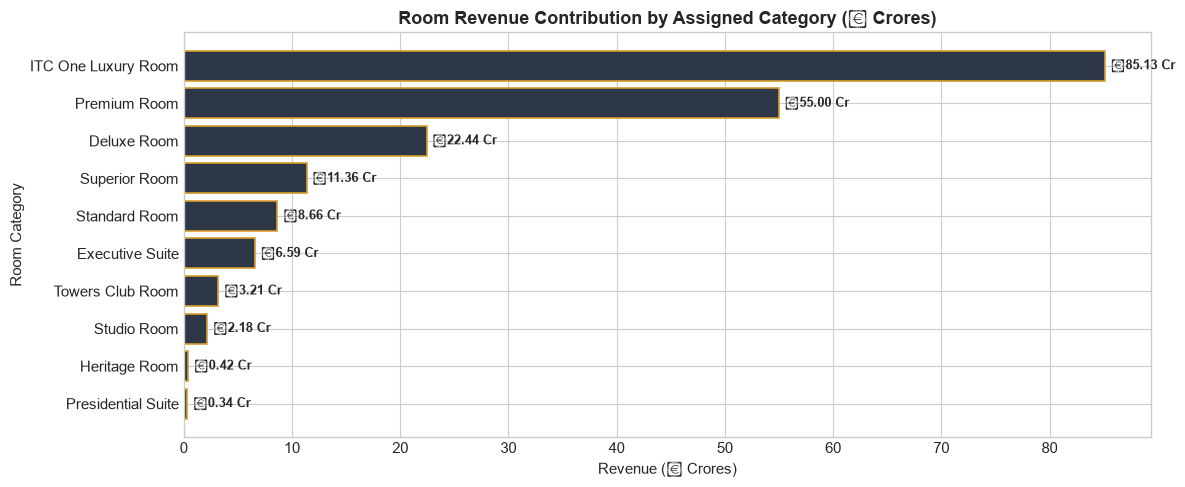

In [4]:
room_col = 'assigned_room' if 'assigned_room' in df_rooms.columns else 'assigned_room_category'
room_cat_summary = df_rooms[df_rooms['is_canceled'] == 0].groupby(room_col).agg(
    bookings=('booking_id', 'count'),
    total_revenue_cr=('room_revenue_inr', lambda x: x.sum() / 1e7),
    avg_adr=('adr_inr', 'mean'),
    avg_stay_nights=('total_nights', 'mean')
).sort_values(by='total_revenue_cr', ascending=False).reset_index()

display(room_cat_summary)

plt.figure(figsize=(12, 5))
bars = plt.barh(room_cat_summary[room_col], room_cat_summary['total_revenue_cr'], color='#2D3748', edgecolor='#D69E2E', linewidth=1.2)
plt.title('Room Revenue Contribution by Assigned Category (₹ Crores)', fontweight='bold', fontsize=13)
plt.xlabel('Revenue (₹ Crores)')
plt.ylabel('Room Category')
plt.gca().invert_yaxis()

for bar in bars:
    w = bar.get_width()
    plt.text(w + 0.5, bar.get_y() + bar.get_height()/2, f'₹{w:,.2f} Cr', va='center', fontsize=9, fontweight='bold')

plt.tight_layout()
plt.show()

## 5. Monthly Seasonality & Occupancy Demand Curve

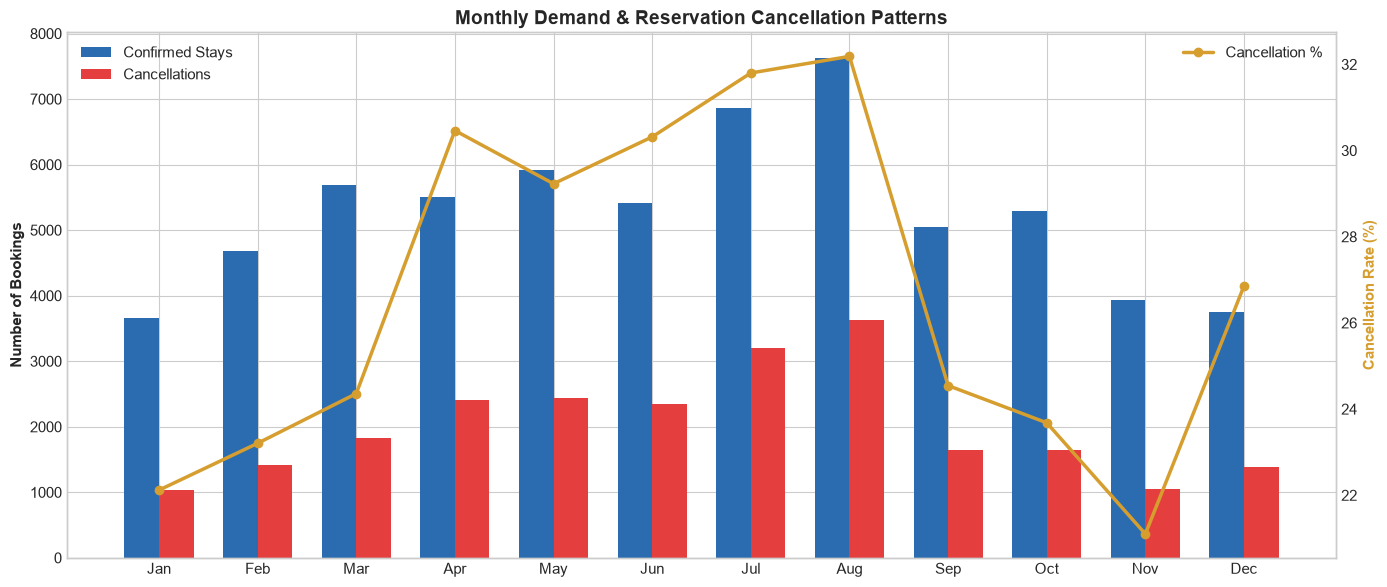

In [5]:
month_col = 'arrival_month' if 'arrival_month' in df_rooms.columns else 'arrival_date_month'
month_order = ['January', 'February', 'March', 'April', 'May', 'June', 
               'July', 'August', 'September', 'October', 'November', 'December']

monthly_trend = df_rooms.groupby([month_col, 'is_canceled']).size().unstack(fill_value=0).reindex(month_order)
monthly_trend.columns = ['Confirmed Stays', 'Cancellations']
monthly_trend['Total Demand'] = monthly_trend['Confirmed Stays'] + monthly_trend['Cancellations']
monthly_trend['Cancellation Rate %'] = (monthly_trend['Cancellations'] / monthly_trend['Total Demand']) * 100

fig, ax1 = plt.subplots(figsize=(14, 6))

x = np.arange(len(month_order))
width = 0.35

ax1.bar(x - width/2, monthly_trend['Confirmed Stays'], width, label='Confirmed Stays', color='#2B6CB0')
ax1.bar(x + width/2, monthly_trend['Cancellations'], width, label='Cancellations', color='#E53E3E')
ax1.set_ylabel('Number of Bookings', fontweight='bold')
ax1.set_xticks(x)
ax1.set_xticklabels([m[:3] for m in month_order], rotation=0)
ax1.set_title('Monthly Demand & Reservation Cancellation Patterns', fontweight='bold', fontsize=14)
ax1.legend(loc='upper left')

ax2 = ax1.twinx()
ax2.plot(x, monthly_trend['Cancellation Rate %'], color='#D69E2E', marker='o', linewidth=2.5, label='Cancellation %')
ax2.set_ylabel('Cancellation Rate (%)', color='#D69E2E', fontweight='bold')
ax2.grid(False)
ax2.legend(loc='upper right')

plt.tight_layout()
plt.show()

## 6. Strategic Takeaways & Academic Recommendations
1. **Dynamic Pricing During Peak Season:** High booking concentration in Oct-Dec warrants a dynamic pricing algorithm.
2. **Cancellation Hedging:** Stricter non-refundable deposit terms during high-demand months can safeguard ₹ Crores in potential lost room yield.
3. **Upsell Optimization:** Premium suites exhibit higher average length of stay (ALOS), providing clear ROI for targeted upgrade promotions at check-in.